---
title: "Lab 6: Insurance Costs"
author: "Shiqi Wu"
format:
  html:
    embed-resources: true
    code-overflow: wrap
---

## Part 1: Data Exploration

In [1]:
import pandas as pd

insurance = pd.read_csv(
    "https://www.dropbox.com/s/bocjjyo1ehr5auz/insurance_costs_1.csv?dl=1"
)

print("Rows and columns:", insurance.shape)

insurance.head()

Rows and columns: (431, 6)


,age,sex,bmi,smoker,region,charges
0,19,female,27.900,yes,southwest,16884.92400
1,33,male,22.705,no,northwest,21984.47061
2,32,male,28.880,no,northwest,3866.85520
3,31,female,25.740,no,southeast,3756.62160
4,60,female,25.840,no,northwest,28923.13692


In [2]:
insurance.info()

print("\nMissing values:")
print(insurance.isna().sum())

print("\nDuplicate rows:", insurance.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 431 entries, 0 to 430
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   age      431 non-null    int64  
 1   sex      431 non-null    str    
 2   bmi      431 non-null    float64
 3   smoker   431 non-null    str    
 4   region   431 non-null    str    
 5   charges  431 non-null    float64
dtypes: float64(2), int64(1), str(3)
memory usage: 27.2 KB

Missing values:
age        0
sex        0
bmi        0
smoker     0
region     0
charges    0
dtype: int64

Duplicate rows: 1


In [3]:
insurance[insurance.duplicated(keep=False)]

,age,sex,bmi,smoker,region,charges
60,19,male,30.59,no,northwest,1639.5631
199,19,male,30.59,no,northwest,1639.5631


In [4]:
insurance_clean = insurance.drop_duplicates().copy()

print("Rows and columns after removing duplicates:", insurance_clean.shape)
print("Remaining duplicate rows:", insurance_clean.duplicated().sum())

Rows and columns after removing duplicates: (430, 6)
Remaining duplicate rows: 0


In [5]:
insurance_clean[["age", "bmi", "charges"]].describe()

,age,bmi,charges
count,430.000000,430.000000,430.000000
mean,38.004651,30.769314,12321.883083
std,16.357315,6.118475,11879.196557
min,18.000000,15.960000,1131.506600
25%,22.000000,26.336250,2722.839375
50%,34.000000,30.590000,9870.992625
75%,55.000000,35.286250,14541.381700
max,64.000000,49.060000,55135.402090


In [8]:
for column in ["sex", "smoker", "region"]:
    print(f"\n{column}:")
    print(insurance_clean[column].value_counts())


sex:
sex
female    225
male      205
Name: count, dtype: int64

smoker:
smoker
no     343
yes     87
Name: count, dtype: int64

region:
region
southeast    125
northeast    108
southwest    103
northwest     94
Name: count, dtype: int64


Answer: The original dataset contains 431 observations and six variables, with no missing values. I found one exact duplicate row and removed the extra copy as a potential duplicate record, leaving 430 observations. Without an individual identifier, I cannot confirm whether the identical rows represent the same person. The categorical variables contain only the expected categories. Ages range from 18 to 64, BMI ranges from 15.96 to 49.06, and charges are all positive. These checks do not reveal clearly invalid values, so I retained the remaining observations, including those with high charges. Mean charges are 12321.88 dollars, compared with median charges of 9870.99 dollars, suggesting possible right skew that I will examine using plots.

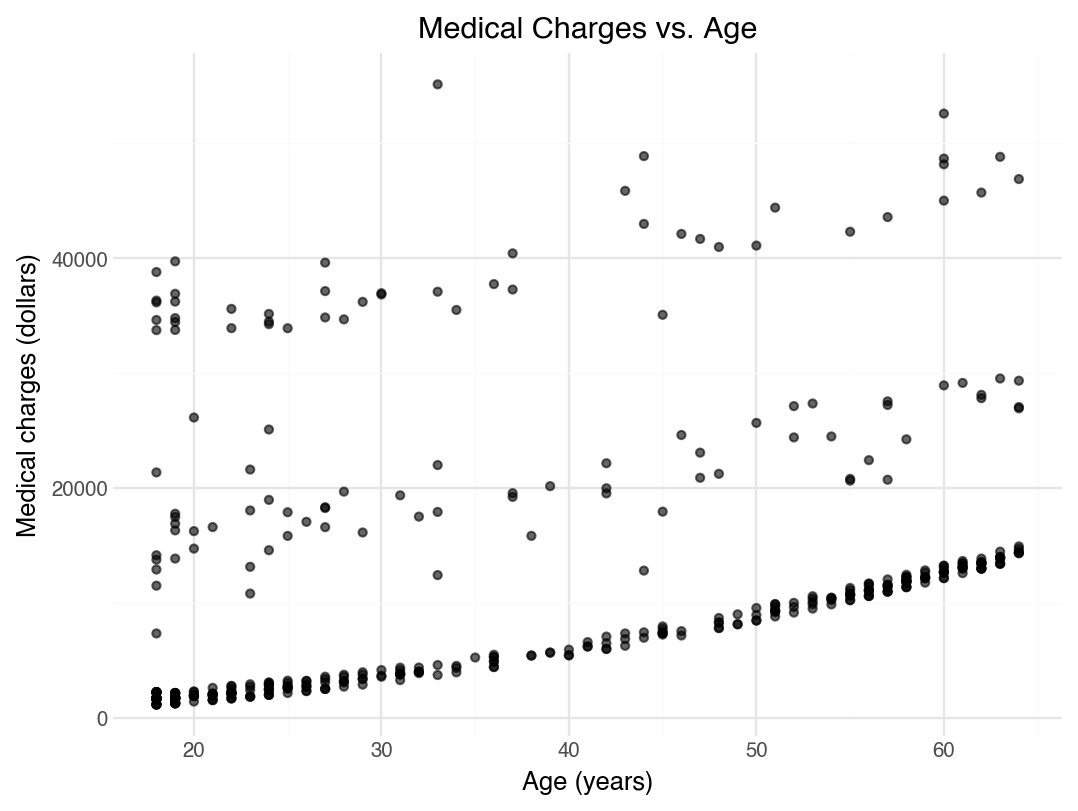

In [9]:
from plotnine import ggplot, aes, geom_point, labs, theme_minimal

(
    ggplot(insurance_clean, aes(x="age", y="charges"))
    + geom_point(alpha=0.6)
    + labs(
        title="Medical Charges vs. Age",
        x="Age (years)",
        y="Medical charges (dollars)"
    )
    + theme_minimal()
)

Answer: Medical charges generally increase with age, particularly along the dense lower band of observations. However, charges vary substantially among individuals of similar ages, with some younger individuals also having high charges. This suggests that age may be useful for predicting medical charges, but age alone does not explain all of the variation.

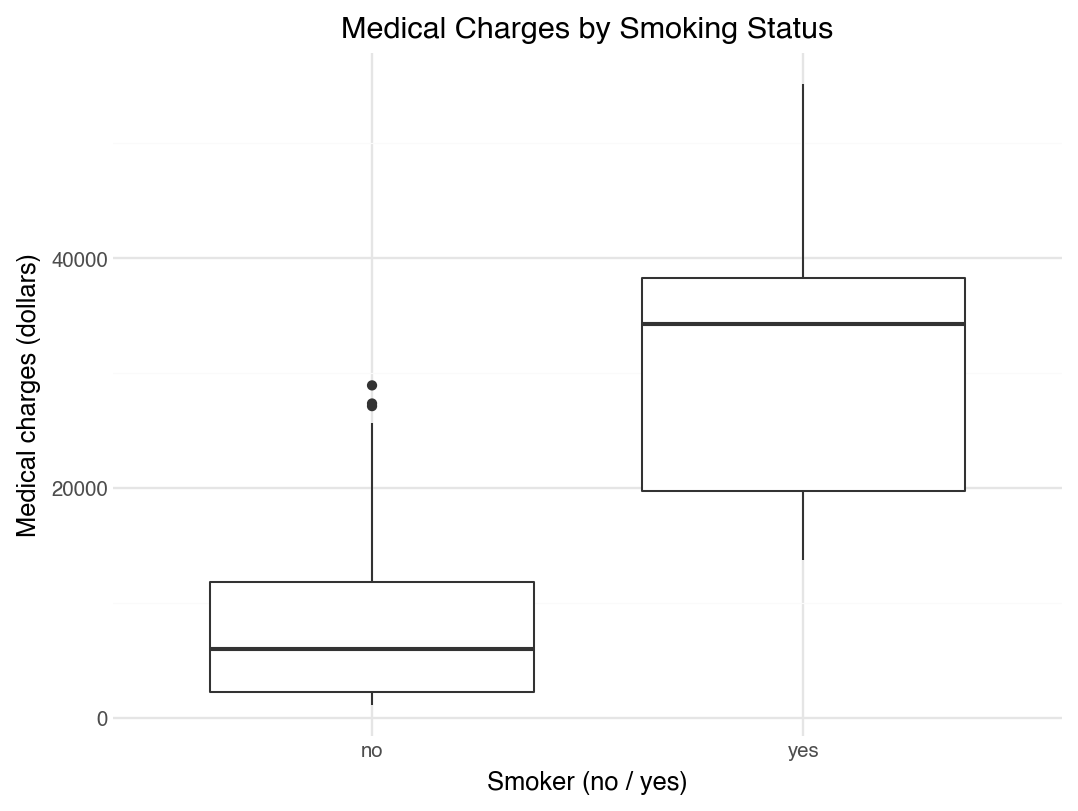

In [10]:
from plotnine import geom_boxplot

(
    ggplot(insurance_clean, aes(x="smoker", y="charges"))
    + geom_boxplot()
    + labs(
        title="Medical Charges by Smoking Status",
        x="Smoker (no / yes)",
        y="Medical charges (dollars)"
    )
    + theme_minimal()
)

Answer: Smokers have substantially higher median medical charges than non-smokers. The larger interquartile range among smokers also indicates greater variability in the middle 50% of their charges. Although the groups overlap, the difference suggests that smoking status may be useful for predicting medical charges. This plot shows an association, not evidence of causation.

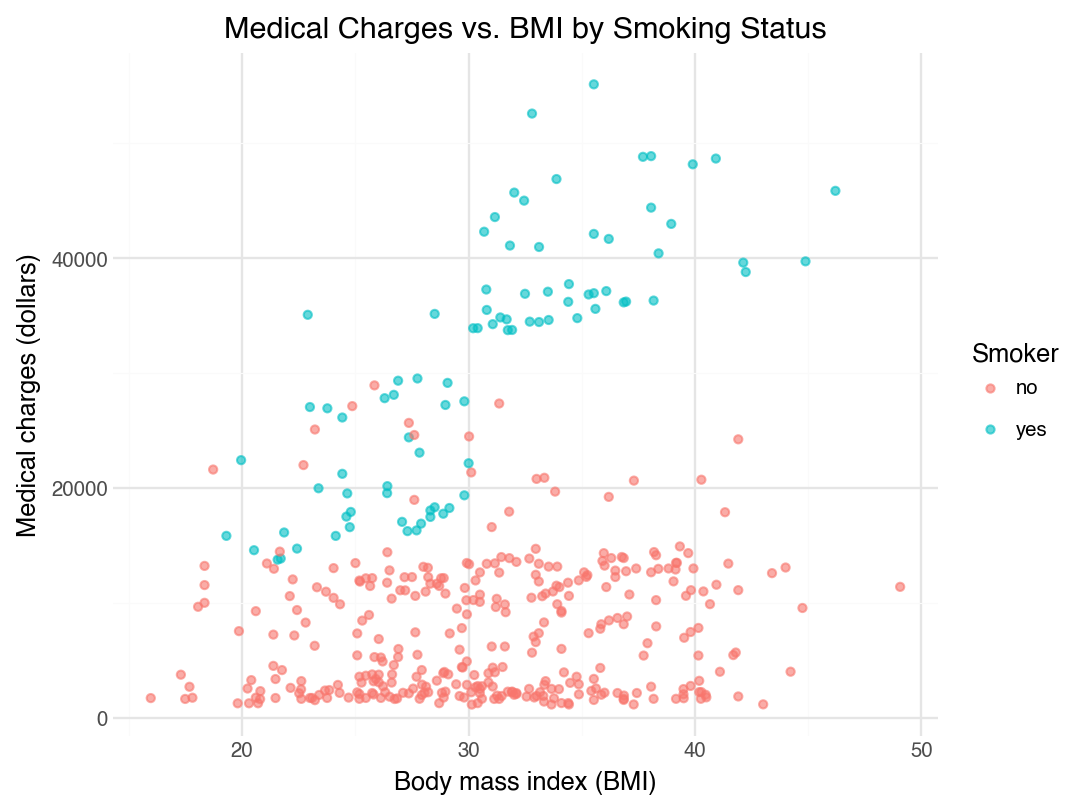

In [11]:
(
    ggplot(
        insurance_clean,
        aes(x="bmi", y="charges", color="smoker")
    )
    + geom_point(alpha=0.6)
    + labs(
        title="Medical Charges vs. BMI by Smoking Status",
        x="Body mass index (BMI)",
        y="Medical charges (dollars)",
        color="Smoker"
    )
    + theme_minimal()
)

Answer: Among smokers, higher BMI is associated with substantially higher medical charges, particularly for BMI values above approximately 30. Among non-smokers, the relationship between BMI and charges appears much weaker. This suggests that the association between BMI and medical charges may differ by smoking status, making an interaction between BMI and smoking status worth considering in the regression models. These patterns describe associations rather than causal effects.

## Part 2: Linear Regression

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

X = insurance_clean.drop(columns="charges")
y = insurance_clean["charges"]

cv = KFold(n_splits=10, shuffle=True, random_state=42)

lr1_preprocessor = ColumnTransformer([
    ("numeric", "passthrough", ["age", "bmi"]),
    ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"),
     ["smoker"])
])

lr1 = Pipeline([
    ("preprocessor", lr1_preprocessor),
    ("model", LinearRegression())
])

lr1_scores = cross_val_score(
    lr1,
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

lr1_rmse = -lr1_scores.mean()

print(f"Linear regression 1 CV RMSE: {lr1_rmse:.2f} dollars")

Linear regression 1 CV RMSE: 5563.42 dollars


In [13]:
lr2_preprocessor = ColumnTransformer([
    ("numeric", "passthrough", ["age", "bmi"]),
    ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"),
     ["sex", "smoker", "region"])
])

lr2 = Pipeline([
    ("preprocessor", lr2_preprocessor),
    ("model", LinearRegression())
])

lr2_scores = cross_val_score(
    lr2,
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

lr2_rmse = -lr2_scores.mean()

print(f"Linear regression 1 CV RMSE: {lr1_rmse:.2f} dollars")
print(f"Linear regression 2 CV RMSE: {lr2_rmse:.2f} dollars")

Linear regression 1 CV RMSE: 5563.42 dollars
Linear regression 2 CV RMSE: 5606.32 dollars


In [14]:
from sklearn.preprocessing import PolynomialFeatures, FunctionTransformer

def add_bmi_smoker(data):
    data = data.copy()
    data["bmi_smoker"] = (
        data["bmi"] * (data["smoker"] == "yes").astype(int)
    )
    return data

lr3_preprocessor = ColumnTransformer([
    ("age_polynomial",
     PolynomialFeatures(degree=2, include_bias=False),
     ["age"]),
    ("numeric", "passthrough", ["bmi", "bmi_smoker"]),
    ("categorical", OneHotEncoder(drop="first", handle_unknown="ignore"),
     ["sex", "smoker", "region"])
])

lr3 = Pipeline([
    ("interaction", FunctionTransformer(add_bmi_smoker)),
    ("preprocessor", lr3_preprocessor),
    ("model", LinearRegression())
])

lr3_scores = cross_val_score(
    lr3,
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

lr3_rmse = -lr3_scores.mean()

print(f"Linear regression 1 CV RMSE: {lr1_rmse:.2f} dollars")
print(f"Linear regression 2 CV RMSE: {lr2_rmse:.2f} dollars")
print(f"Linear regression 3 CV RMSE: {lr3_rmse:.2f} dollars")

Linear regression 1 CV RMSE: 5563.42 dollars
Linear regression 2 CV RMSE: 5606.32 dollars
Linear regression 3 CV RMSE: 4312.86 dollars


In [15]:
from sklearn.base import clone

best_lr = clone(lr3)
best_lr.fit(X, y)

lr_coefficients = pd.DataFrame({
    "Feature": best_lr.named_steps[
        "preprocessor"
    ].get_feature_names_out(),
    "Coefficient": best_lr.named_steps["model"].coef_
})

print(
    f"Intercept: "
    f"{best_lr.named_steps['model'].intercept_:.2f} dollars"
)

lr_coefficients

Intercept: -63.44 dollars


,Feature,Coefficient
0,age_polynomial__age,156.426006
1,age_polynomial__age^2,1.241331
2,numeric__bmi,13.652535
3,numeric__bmi_smoker,1501.486976
4,categorical__sex_male,-430.677416
5,categorical__smoker_yes,-21981.490777
6,categorical__region_northwest,-755.468747
7,categorical__region_southeast,-1181.867111
8,categorical__region_southwest,-1152.741111


Answer: I selected Model 3 because it has the lowest mean 10-fold cross-validation RMSE: 4312.86 dollars, compared with 5563.42 dollars for Model 1 and 5606.32 dollars for Model 2. All models used the same folds. Adding sex and region alone did not improve the estimated prediction error, but adding the age-squared term and the BMI-by-smoking interaction substantially improved performance. Model 3 is therefore the best of the three linear regression models tested.

Holding the other predictors constant, the age-related terms are 156.43 × age + 1.24133 × age², so the predicted increase in charges per additional year becomes larger at older ages. For example, moving from age 30 to 31 increases predicted charges by approximately 232.15 dollars. For non-smokers, a one-unit increase in BMI corresponds to an increase of approximately 13.65 dollars in predicted charges. The BMI-by-smoking interaction coefficient is 1501.49, giving smokers a combined BMI slope of approximately 1515.14 dollars per unit. The smoker coefficient is -21981.49, but the predicted smoker-versus-non-smoker difference is -21981.49 + 1501.49 × BMI, rather than a fixed negative difference. At BMI 30, smokers have predicted charges approximately 23063 dollars higher. Males have predicted charges 430.68 dollars lower than females. Compared with the northeast, predicted charges are 755.47 dollars lower in the northwest, 1181.87 dollars lower in the southeast, and 1152.74 dollars lower in the southwest. The intercept is -63.44 dollars for a female non-smoker in the northeast with age and BMI both zero; because these numerical values are outside the observed ranges, the intercept has little practical meaning. These coefficients describe conditional model associations, not causal effects.

## Part 3: K-Nearest Neighbors Regression

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor

knn1_preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), ["age", "bmi"]),
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     ["smoker"])
])

knn1 = Pipeline([
    ("preprocessor", knn1_preprocessor),
    ("model", KNeighborsRegressor(n_neighbors=5))
])

knn1_scores = cross_val_score(
    knn1,
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

knn1_rmse = -knn1_scores.mean()

print(f"KNN 1 (k=5) CV RMSE: {knn1_rmse:.2f} dollars")

KNN 1 (k=5) CV RMSE: 4481.60 dollars


In [17]:
knn2_preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), ["age", "bmi"]),
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     ["sex", "smoker", "region"])
])

knn2 = Pipeline([
    ("preprocessor", knn2_preprocessor),
    ("model", KNeighborsRegressor(n_neighbors=5))
])

knn2_scores = cross_val_score(
    knn2,
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

knn2_rmse = -knn2_scores.mean()

print(f"KNN 1 (k=5) CV RMSE: {knn1_rmse:.2f} dollars")
print(f"KNN 2 (k=5) CV RMSE: {knn2_rmse:.2f} dollars")

KNN 1 (k=5) CV RMSE: 4481.60 dollars
KNN 2 (k=5) CV RMSE: 5851.63 dollars


In [18]:
knn3 = clone(knn1).set_params(model__n_neighbors=10)

knn3_scores = cross_val_score(
    knn3,
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

knn3_rmse = -knn3_scores.mean()

print(f"KNN 1 (k=5, three predictors) CV RMSE: {knn1_rmse:.2f} dollars")
print(f"KNN 2 (k=5, five predictors) CV RMSE: {knn2_rmse:.2f} dollars")
print(f"KNN 3 (k=10, three predictors) CV RMSE: {knn3_rmse:.2f} dollars")

KNN 1 (k=5, three predictors) CV RMSE: 4481.60 dollars
KNN 2 (k=5, five predictors) CV RMSE: 5851.63 dollars
KNN 3 (k=10, three predictors) CV RMSE: 4466.02 dollars


In [19]:
best_knn = clone(knn3)
best_knn.fit(X, y)

print(
    f"Selected KNN: "
    f"k={best_knn.named_steps['model'].n_neighbors}"
)
print(f"Training observations: {len(X)}")

Selected KNN: k=10
Training observations: 430


Answer: I selected KNN Model 3, which uses age, BMI, and smoking status with k=10. Its mean 10-fold cross-validation RMSE is 4466.02 dollars, compared with 4481.60 dollars for Model 1, which uses the same predictors with k=5, and 5851.63 dollars for Model 2, which adds sex and region with k=5. All models use the same folds, standardize numerical predictors, and one-hot encode categorical predictors within their pipelines. Adding sex and region increased the estimated prediction error, while increasing k from 5 to 10 with the three-predictor set slightly reduced it. Model 3 has the lowest estimated error among the KNN models tested, although its advantage over Model 1 is small. I fitted the selected pipeline on all 430 cleaned observations so it can later predict the new data without being refitted.

## Part 4: Regression Decision Tree Models

In [20]:
from sklearn.tree import DecisionTreeRegressor

tree1_preprocessor = ColumnTransformer([
    ("numeric", "passthrough", ["age", "bmi"]),
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     ["smoker"])
])

tree1 = Pipeline([
    ("preprocessor", tree1_preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=3,
        random_state=42
    ))
])

tree1_scores = cross_val_score(
    tree1,
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

tree1_rmse = -tree1_scores.mean()

print(f"Tree 1 (max depth=3) CV RMSE: {tree1_rmse:.2f} dollars")

Tree 1 (max depth=3) CV RMSE: 4121.88 dollars


In [21]:
tree2_preprocessor = ColumnTransformer([
    ("numeric", "passthrough", ["age", "bmi"]),
    ("categorical", OneHotEncoder(handle_unknown="ignore"),
     ["sex", "smoker", "region"])
])

tree2 = Pipeline([
    ("preprocessor", tree2_preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=3,
        random_state=42
    ))
])

tree2_scores = cross_val_score(
    tree2,
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

tree2_rmse = -tree2_scores.mean()

print(f"Tree 1 (depth=3, three predictors) CV RMSE: {tree1_rmse:.2f} dollars")
print(f"Tree 2 (depth=3, five predictors) CV RMSE: {tree2_rmse:.2f} dollars")

Tree 1 (depth=3, three predictors) CV RMSE: 4121.88 dollars
Tree 2 (depth=3, five predictors) CV RMSE: 4121.88 dollars


In [22]:
tree3 = clone(tree1).set_params(model__max_depth=5)

tree3_scores = cross_val_score(
    tree3,
    X,
    y,
    cv=cv,
    scoring="neg_root_mean_squared_error"
)

tree3_rmse = -tree3_scores.mean()

print(f"Tree 1 (depth=3, three predictors) CV RMSE: {tree1_rmse:.2f} dollars")
print(f"Tree 2 (depth=3, five predictors) CV RMSE: {tree2_rmse:.2f} dollars")
print(f"Tree 3 (depth=5, three predictors) CV RMSE: {tree3_rmse:.2f} dollars")

Tree 1 (depth=3, three predictors) CV RMSE: 4121.88 dollars
Tree 2 (depth=3, five predictors) CV RMSE: 4121.88 dollars
Tree 3 (depth=5, three predictors) CV RMSE: 4908.84 dollars


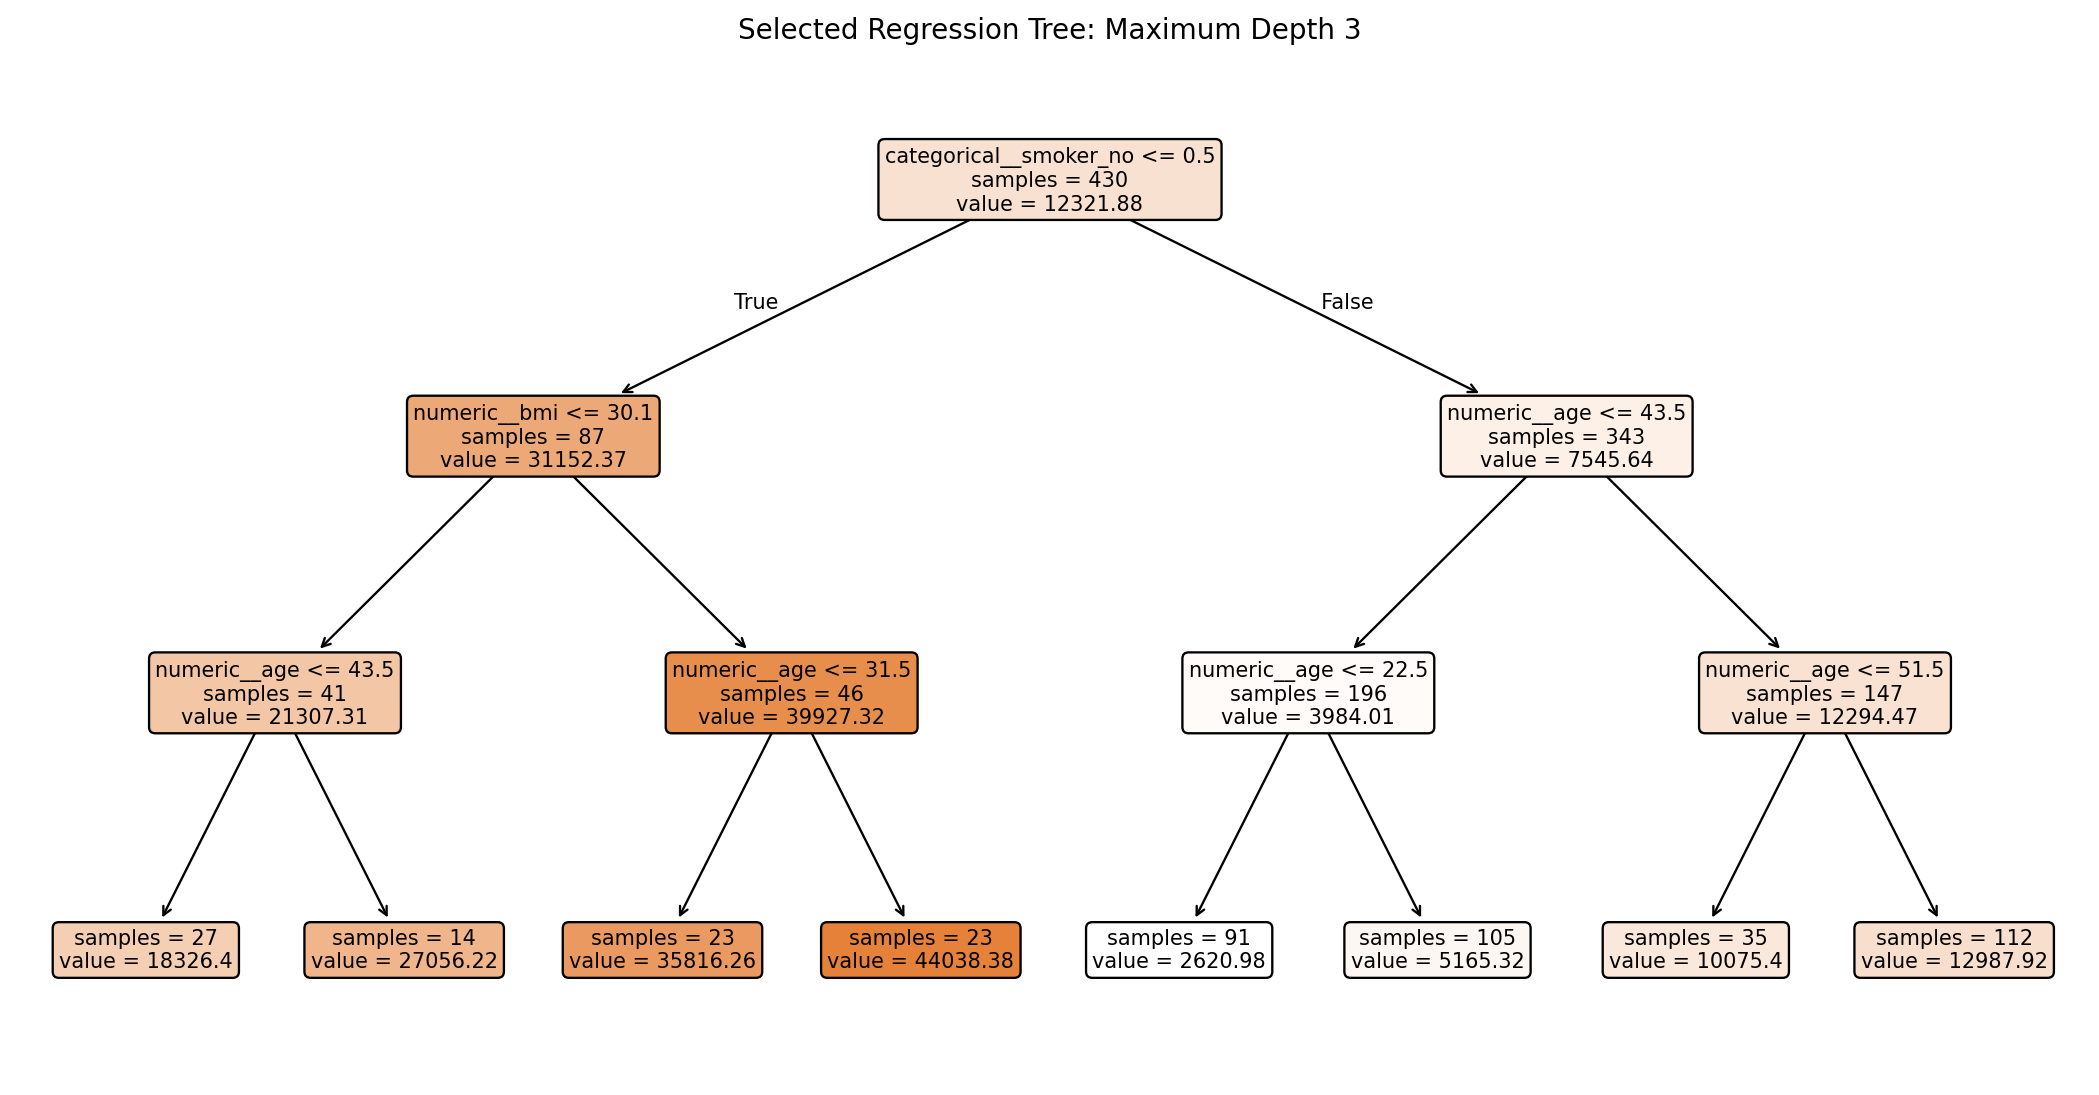

In [23]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

best_tree = clone(tree1)
best_tree.fit(X, y)

tree_feature_names = (
    best_tree.named_steps["preprocessor"].get_feature_names_out()
)

fig, ax = plt.subplots(figsize=(16, 8))

plot_tree(
    best_tree.named_steps["model"],
    feature_names=tree_feature_names,
    filled=True,
    rounded=True,
    impurity=False,
    precision=2,
    fontsize=9,
    ax=ax
)

ax.set_title("Selected Regression Tree: Maximum Depth 3")
plt.show()

Answer: I selected Tree Model 1, which uses age, BMI, and smoking status with a maximum depth of 3. Its mean 10-fold cross-validation RMSE is 4121.88 dollars, the same rounded value as Model 2 using all five predictors, and lower than 4908.84 dollars for the depth-5 Model 3. I prefer Model 1 to Model 2 because it requires fewer predictors. Increasing the depth did not improve the estimated prediction error.

The selected tree first separates smokers from non-smokers. For smokers, it next splits at a BMI of approximately 30.1, then by age. Smokers above this BMI threshold have predicted charges of 35816.26 dollars if their age is at most 31.5, and 44038.38 dollars if older. Non-smokers are divided by age, with predicted charges ranging from 2620.98 dollars for those aged at most 22.5 to 12987.92 dollars for those older than 51.5. Each leaf predicts the mean charges of the training observations in that group. I fitted the selected tree pipeline on all 430 cleaned observations for later prediction on the new data.

## Part 5: New Data

In [24]:
insurance_new = pd.read_csv(
    "https://www.dropbox.com/s/sky86agc4s8c6qe/insurance_costs_2.csv?dl=1"
)

print("New data rows and columns:", insurance_new.shape)

print("\nMissing values:")
print(insurance_new.isna().sum())

insurance_new.head()

New data rows and columns: (143, 6)

Missing values:
age        0
sex        0
bmi        0
smoker     0
region     0
charges    0
dtype: int64


,age,sex,bmi,smoker,region,charges
0,23,male,34.400,no,southwest,1826.84300
1,56,male,40.300,no,southwest,10602.38500
2,18,male,34.100,no,southeast,1137.01100
3,63,female,23.085,no,northeast,14451.83515
4,63,male,28.310,no,northwest,13770.09790


In [25]:
from sklearn.metrics import root_mean_squared_error

X_new = insurance_new.drop(columns="charges")
y_new = insurance_new["charges"]

lr_new_predictions = best_lr.predict(X_new)
knn_new_predictions = best_knn.predict(X_new)
tree_new_predictions = best_tree.predict(X_new)

new_data_results = pd.DataFrame({
    "Model": [
        "Linear regression Model 3",
        "KNN Model 3 (k=10)",
        "Tree Model 1 (depth=3)"
    ],
    "New-data RMSE (dollars)": [
        root_mean_squared_error(y_new, lr_new_predictions),
        root_mean_squared_error(y_new, knn_new_predictions),
        root_mean_squared_error(y_new, tree_new_predictions)
    ]
})

new_data_results

,Model,New-data RMSE (dollars)
0,Linear regression Model 3,4725.402951
1,KNN Model 3 (k=10),5459.254527
2,Tree Model 1 (depth=3),4695.779255


Answer: The selected regression tree performs best on the 143 new observations, with an RMSE of 4695.78 dollars, compared with 4725.40 dollars for the selected linear regression and 5459.25 dollars for the selected KNN. The tree's RMSE is only 29.62 dollars lower than the linear regression's, so its advantage on this dataset is small. These results do not establish that the tree will always perform best on future data. All three pipelines were selected using cross-validation and fitted on the original cleaned dataset. I used their existing fitted transformations and models to predict the new data without refitting or tuning them on it.